# CSLC-NRB SAOCOM demo

In [ ]:
"""
File Name: cslc_nrb_saocom.ipynb

Author:
    Alessio Morea
    B-Open Solutions srl

Date: August 2025

Description:
------------
This notebook processes SAOCOM data to generate Analysis-Ready Data (ARD) products, specifically CSLC and NRB.
Options and configuration parameters about some processing steps can be set
by the user.

Usage:
------
To use this script, define the following parameters:

    - dem_path:  Path to the input Digital Elevation Model (DEM) file.
    - slcs_path: Path to the directory containing the SLCs
    - wdir_path_static: Directory to save static data
    - wdir_path_tmp: Directory to save dynamic data
    - reference_date:  The acquisition date of the reference image
    - spacing: The output pixel spacing for the resampled DEM.

Optionally, set the processing parameters:
    - etad_path:  Path to the folder containing ETAD correction files.
    - orbit_path: Path to the folder containing precise orbit files 
    - chunks: The chunk size to use for parallel computations
    - crs: The target CRS for DEM reprojection 
    - recompute: Set to True to force recomputation of files in the static directory. Defaults to False.
    - n_jobs:  The number of parallel workers to use.
    - job_memory: The memory allocated to each worker
"""

In [ ]:
%load_ext autoreload
%autoreload 2
import warnings

import os
import time
import pyproj
import numpy as np
import xarray as xr
import s1_ard_core.computing.io
import s1_ard_core.computing.dem
import s1_ard_core.computing.simul
import s1_ard_core.computing.shiroma
import s1_ard_core.computing.matching

import s1_ard_core.computing.slc
import s1_ard_core.computing.orbit
import s1_ard_core.computing.etad
import s1_ard_core.computing.gslc
import s1_ard_core.computing.coreg
from s1_ard_core.computing.logger import logger
from pyproj.transformer import TransformerGroup
warnings.filterwarnings("ignore")


### Processor configuration

Define paths and variables

In [ ]:
prefix_path = "s3://bopen-sar/TEST_AM/SAOCOM"
dem_path = f"s3://bopen-sar/ARD-ROSE-L/PHASE_1/DEMONSTRATOR/NRB/SAOCOM/Naples/ASC/S4/dem"
wdir_path_static = f"{prefix_path}/WDIR_STATIC"
wdir_path_tmp = f"{prefix_path}/WDIR_DYNAMIC"
slcs_path = f"s3://bopen-sar/ARD-ROSE-L/PHASE_1/DEMONSTRATOR/NRB/SAOCOM/Naples/ASC/S4/slcs/orig"
etad_path = None
orbit_path = None
reference_date = "2020-04-23T04:51:27.189461"
chunks = {"x": 1024, "y": 1024}
spacing = {"x": 10, "y": 10}
crs = None
recompute = False

### Create Dask Client

In [ ]:
os.environ["PROJ_DATA"] = pyproj.datadir.get_data_dir()
type, n_jobs, job_memory = ["LOCAL", 16, "16GB"]
client = s1_ard_core.computing.computation.create_client(type, n_jobs, job_memory)
client

### Read L1 Data

In [ ]:
files = s1_ard_core.computing.io.glob(f"{slcs_path}/2*")

In [ ]:
slcs = xr.DataTree()
pol = "V:V"
for f in files:
    date = f.split("/")[-1]
    s = s1_ard_core.computing.io.read(f, consolidate_metadata=True)
    s = s.assign_coords({"polarization": pol}).expand_dims(polarization=1)
    s.slc.attrs = {pol: s.slc.attrs}
    slcs[f"orig/{date}/measurements"] = s
    slcs[f"orig/{date}/conditions"] = xr.Dataset()
    slcs[f"orig/{date}/quality"] = xr.Dataset()

In [ ]:
bbox = s1_ard_core.computing.slc.get_bbox(slcs)
multiburst = True if "bursts" in slcs else False
acquisition_dates = s1_ard_core.computing.slc.extract_acquisition_dates(slcs, multiburst=multiburst)
if orbit_path is not None:
    slcs = s1_ard_core.computing.orbit.import_ORBIT(slcs, acquisition_dates, orbit_path, multiburst=multiburst)
if etad_path is not None:
    slcs = s1_ard_core.computing.etad.import_ETAD(
        slcs, acquisition_dates, etad_path, multiburst=multiburst, wdir_path=wdir_path_tmp
    )

### Import DEM and Resampling

In [ ]:
dem = s1_ard_core.computing.dem.import_dem(
    bbox=bbox,
    dem_type=dem_path,
    working_dir=wdir_path_tmp,
    chunks=chunks,
)

In [ ]:
if crs is None:
    crs = s1_ard_core.computing.dem.get_default_epsg(dem)
dem_resampled = s1_ard_core.computing.dem.dem_reproject(
    dem, spacing, crs, chunks=chunks, data_path=wdir_path_tmp, enable_dask=True
)

### Reference Geometry

In [ ]:
dem_resampled = s1_ard_core.computing.io.read(f"{wdir_path_tmp}/dem_resampled", consolidate_metadata=False)

In [ ]:
orbits = s1_ard_core.computing.slc.extract_orbits(
    slcs,
    multiburst=multiburst,
    acquisition_date=[reference_date],
)
orbits = orbits.sel(acquisition_date=[reference_date])
chunks = {k: v[0] for k, v in dem_resampled.chunksizes.items() if k in ["x", "y"]}
chunks["acquisition_date"] = 1
simulation = s1_ard_core.computing.simul.dem_to_radar(
    dem_resampled.z,
    orbits,
    working_dir=wdir_path_static,
    chunks=chunks,
    read=True,
    master_image=True,
    recompute=recompute,
)
simulation_ml = s1_ard_core.computing.simul.extract_simulation_ml(
    simulation, reference_date, wdir_path_static, recompute=recompute
)

### Rasterization and RTC (Area Based)

In [ ]:
t0 = time.time()
s1_ard_core.computing.shiroma.stack_geometry(
    slcs,
    simulation,
    simulation_ml,
    working_directory_static=wdir_path_static,
    working_directory_tmp=wdir_path_tmp,
    reference_date=reference_date,
    chunk_length=max([i for i in chunks.values()]),
    recompute=recompute,
    multiburst=multiburst,
)
t1 = time.time() - t0
print(f"TIME RASTERIZATION + RTC_AP: {t1:.8f} s")

### Compute Radar Shadow Mask

In [ ]:
t0 = time.time()
s1_ard_core.computing.shiroma.stack_mask(
    slcs,
    simulation,
    simulation_ml,
    working_directory_static=wdir_path_static,
    reference_date=reference_date,
    recompute=recompute,
    multiburst=multiburst,
)
t1 = time.time() - t0
print(f"TIME MASK SHADOW: {t1:.4f} s")

## CSLC product generation 

In [ ]:
# Orbit information extraction from the slcs structure
orbits = s1_ard_core.computing.slc.extract_orbits(slcs, multiburst=multiburst)

# I need to remove the reference date since I already have the simulation for it
orbits = orbits.where(orbits.acquisition_date != reference_date, drop=True)
chunks = {k: v[0] for k, v in dem_resampled.chunksizes.items() if k in ["x", "y"]}
chunks["acquisition_date"] = 1
simulation_coreg = s1_ard_core.computing.simul.dem_to_radar(
    dem_resampled.z,
    orbits,
    working_dir=wdir_path_tmp,
    chunks=chunks,
    client_options={"type": "LOCAL"},
    read=True,
    master_image=False,
)
simulation_combined = xr.concat([simulation, simulation_coreg], dim="acquisition_date").chunk(
    {k: v[0] for k, v in simulation.chunksizes.items()}
)

simulation_combined = s1_ard_core.computing.io.write(
    simulation_combined,
    f"{wdir_path_tmp}/simulation.combined",
    mode="w",
    consolidated=False,
)

### Coregistration

In [ ]:
simulation_combined = s1_ard_core.computing.io.read(f"{wdir_path_tmp}/simulation.combined", consolidate_metadata=False)

In [ ]:
t0 = time.time()
slcs = s1_ard_core.computing.coreg.stack_coregistration(
    slcs,
    simulation_combined,
    simulation_ml,
    reference_date,
    multiburst=multiburst,
    working_directory=wdir_path_tmp,
    mission="saocom",
)
t1 = time.time() - t0
print(f"TIME COREG: {t1:.8f} s")

In [ ]:
cstack = slcs.coreg.measurements.cstack.drop_vars(["polarization"]).squeeze()

In [ ]:
options = {}
disparity = s1_ard_core.computing.matching.compute_pearson_coefficient(
    slcs.coreg.measurements.cstack.drop_vars(["polarization"]).squeeze(),
    reference_date,
    options.get("matching_size", [256, 256]),
    options.get("matching_step", [256, 256]),
    options.get("matching_wsearch", [5, 5]),
    mode=options.get("matching_mode", "amplitude"),
    forward=options.get("matching_forward", False),
    dim=options.get("matching_dim", [1, 1]),
    type="times",
    pathces_path=options.get("patches_path", None),
    block_size=options.get("block_size", 10),
)

In [ ]:
y_poly, x_poly = s1_ard_core.computing.computation.map_blocks(
    s1_ard_core.computing.matching.polyfit,
    (disparity, slcs.coreg.measurements.drg, slcs.coreg.measurements.daz),
    args=(slcs.orig[reference_date].measurements.slc.attrs[pol]),
    kwargs={
        "deg": options.get("poly_deg", 3),
        "cohe_th": options.get("poly_cohe_th", 0.3),
        "norm": options.get("poly_norm", 1),
    },
    chunksizes={"acquisition_date": 1},
    enable_dask=False,
    scheduler=options.get("scheduler", "threads"),
)

In [ ]:
t0 = time.time()
slcs = s1_ard_core.computing.coreg.stack_coregistration(
    slcs,
    simulation_combined,
    simulation_ml,
    reference_date,
    multiburst=multiburst,
    working_directory=f"{wdir_path_tmp}",
    mission="saocom",
    x_poly=x_poly,
    y_poly=y_poly,
)
t1 = time.time() - t0
print(f"TIME COREG: {t1:.8f} s")

## NRB product generation - Area based projection

In [ ]:
slcs["coreg"] = s1_ard_core.computing.io.read(f"{wdir_path_tmp}/data", consolidate_metadata=True)["coreg"]

In [ ]:
t0 = time.time()
gslcs = s1_ard_core.computing.gslc.stack_shiroma(
    slcs=slcs,
    reference_date=reference_date,
    multiburst=multiburst,
    coreg=True,
    working_directory_static=wdir_path_static,
    working_directory_tmp=wdir_path_tmp,
    recompute=recompute,
)
t1 = time.time() - t0
print(f"TIME FLATTENING + PROJECTION: {t1:.4f} s")

In [ ]:
t0 = time.time()
nrb = s1_ard_core.computing.gslc.mosaic(gslcs, wdir_path_tmp, enable_dask=True)
t1 = time.time() - t0
print(f"TIME MOSAIC: {t1:.4f} s")

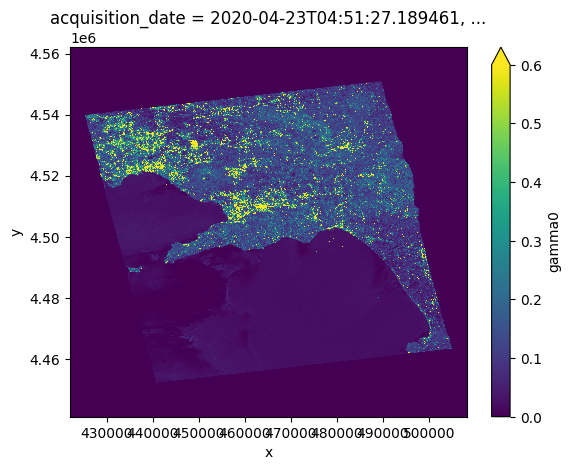

In [3]:
nrb.gamma0[0, 0].coarsen(x=10, y=10, boundary="trim").mean().plot.imshow(vmin=0, vmax=0.6)